# How fast can a private learner adapt? Simulations for NBFS

This notebook runs the experiments for the mid-term report. It checks, empirically, the main claims:

1. **Privacy forces a minimum adaptation window, and it scales linearly in $k/\varepsilon$.** NBFS's empirical adaptation threshold should grow like $k/\varepsilon$, while a non-private learner's threshold should not depend on $k$ or $\varepsilon$ at all.
2. **Blocking ("freezing") is what makes the scaling linear.** A private learner that adds noise every round instead of once per block needs a window that grows like $(k/\varepsilon)^2$.
3. **Forgetting is necessary.** Learners without fixed-share mixing, private or not, never recover on short windows after a change.
4. **The proved bounds bracket what we observe.**

Requirements: `numpy`, `matplotlib`, `numba` (`pip install numba`). Total runtime is a few minutes on a laptop. Figures are saved as PDF and PNG in `figures/`.

In [1]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
from numba import njit

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
})
COLORS = {
    "NBFS": "#1f4e9c",
    "NBFS (theory step size)": "#6f8fc9",
    "Private per-round fixed share": "#e07b00",
    "Private blocked Hedge (no forgetting)": "#8e44ad",
    "Fixed share (non-private)": "#222222",
    "Hedge (non-private, no forgetting)": "#9a9a9a",
}
def save(fig, name):
    fig.savefig(f"figures/{name}.pdf", bbox_inches="tight")
    fig.savefig(f"figures/{name}.png", bbox_inches="tight")

## 1. The environment: churning clients with private preferences

* There are $K$ actions and $T$ rounds. Clients arrive one after another, and each client is served for $k$ consecutive rounds (its *tenure*).
* Each client has a private *type*, its favourite action. The loss is $\ell_t(i)=0$ if $i$ is the served client's type and $1$ otherwise.
* The population changes in *regimes* of length $P$. Within a regime, a client's type equals the regime's best action with probability $q$, and is a uniformly random other action otherwise. At every regime change the best action switches to a different one.

With $q=0.75$ and $K=4$, the best action has expected loss $0.25$ and every other action $\approx 0.92$, so an action that has not yet adapted loses about $0.67$ per round.

In [2]:
def make_env(T, K, k, P, q, rng):
    n_reg = int(np.ceil(T / P))
    best = np.empty(n_reg, dtype=np.int64)
    best[0] = rng.integers(K)
    for r in range(1, n_reg):
        b = rng.integers(K - 1)
        best[r] = b if b < best[r - 1] else b + 1
    n_cl = int(np.ceil(T / k))
    bc = best[(np.arange(n_cl) * k) // P]          # regime in which each client arrives
    other = rng.integers(K - 1, size=n_cl)
    other = np.where(other >= bc, other + 1, other)
    types = np.where(rng.random(n_cl) < q, bc, other)
    round_types = np.repeat(types, k)[:T].astype(np.int64)
    switches = np.arange(1, n_reg) * P
    return dict(types=round_types, switches=switches, best=best)

def block_losses(types, K, B):
    # L_b(j) = sum of l_t(j) over the B rounds of block b
    T = len(types); N = -(-T // B)                      # last block may be shorter
    counts = np.bincount((np.arange(T) // B) * K + types, minlength=N * K).reshape(N, K)
    blen = np.full(N, B); blen[-1] = T - B * (N - 1)
    return (blen[:, None] - counts).astype(np.float64)

## 2. The learners

All learners share one routine: exponential weights with fixed-share mixing, run on (possibly noisy) losses.

| Learner | Updates | Noise | Mixing $\alpha$ | Private? |
|---|---|---|---|---|
| **NBFS** (our algorithm) | once per block of $B$ rounds | $\mathrm{Lap}(kK/\varepsilon)$ on each block sum, clipped | $B/T$ | $\varepsilon$-client-DP |
| Private per-round fixed share | every round | $\mathrm{Lap}(kK/\varepsilon)$ on each round's losses, clipped | $1/T$ | $\varepsilon$-client-DP |
| Private blocked Hedge | once per block of $B$ rounds | same as NBFS | $0$ (never forgets) | $\varepsilon$-client-DP |
| Fixed share | every round | none | $1/T$ | no |
| Hedge | every round | none | $0$ | no |

**All three private learners satisfy exactly the same guarantee.** Each adds independent $\mathrm{Lap}(kK/\varepsilon)$ noise to the sums over a partition of time. One client changes those sums by at most $kK$ in $\ell_1$ norm, so the Laplace mechanism gives $\varepsilon$-client-DP, and everything else is post-processing (Lemma 2 of the report). They differ only in *how* they spend the same privacy budget.

NBFS uses the block size from the report, $B=\lceil 4kK\ln T/\varepsilon\rceil$, and the clipping level $M=2(kK/\varepsilon)\ln T$.

In [3]:
@njit(cache=True)
def fixed_share(g, eta, alpha):
    # Exponential weights with fixed-share mixing, computed in the log domain.
    # Returns P[b], the distribution used during step b.
    N, K = g.shape
    P = np.empty((N, K)); logp = np.full(K, -np.log(K)); tmp = np.empty(K)
    for b in range(N):
        for j in range(K):
            P[b, j] = np.exp(logp[j])
        mx = -1e300
        for j in range(K):
            tmp[j] = logp[j] - eta * g[b, j]
            if tmp[j] > mx: mx = tmp[j]
        s = 0.0
        for j in range(K): s += np.exp(tmp[j] - mx)
        lse = mx + np.log(s)
        for j in range(K):
            lw = tmp[j] - lse
            logp[j] = np.log((1.0 - alpha) * np.exp(lw) + alpha / K) if alpha > 0.0 else lw
    return P

def nbfs_params(k, K, eps, T):
    lam = k * K / eps
    M = 2 * lam * np.log(T)
    return lam, M, int(np.ceil(2 * M))

def theory_eta(B, R, K, T, tau):
    # step size from Theorem 3 of the report
    return np.sqrt(8 * B * (np.log(K * T) + 2) / (tau * R ** 2))

def spec(alg, cfg, B=None):
    # returns (block length, noise scale, clip level, mixing rate, range R)
    lam, M, T = cfg["lam"], cfg["M"], cfg["T"]
    Bn = cfg["B"] if B is None else B
    return {
        "NBFS":                                  (Bn, lam, M, Bn / T, Bn + 2 * M),
        "Private per-round fixed share":         (1,  lam, M, 1 / T,  1 + 2 * M),
        "Private blocked Hedge (no forgetting)": (Bn, lam, M, 0.0,    Bn + 2 * M),
        "Fixed share (non-private)":             (1,  0.0, 0, 1 / T,  1.0),
        "Hedge (non-private, no forgetting)":    (1,  0.0, 0, 0.0,    1.0),
    }[alg]

def run(alg, env, cfg, eta, rng, B=None):
    # returns the learner's expected loss in every round
    b, lam, M, alpha, _ = spec(alg, cfg, B)
    L = env["L"].get(b)
    if L is None:
        L = env["L"][b] = block_losses(env["types"], cfg["K"], b)
    g = np.clip(L + rng.laplace(0.0, lam, size=L.shape), -M, b + M) if lam > 0 else L
    Pm = fixed_share(g, eta, alpha)
    return 1.0 - Pm[np.arange(len(env["types"])) // b, env["types"]]

## 3. How we measure adaptation

For each window length $\tau$ we look at the window of $\tau$ rounds that starts right at a regime change, which is the hardest window in this environment. We compute the **normalized window regret**
$$\frac{1}{\tau}\Big(\textstyle\sum_{t\in I}\E[\ell_t(a_t)] - \min_i \sum_{t\in I}\ell_t(i)\Big),$$
and average it over all changes and random seeds.

The **empirical adaptation threshold** $\hat\tau_\gamma$ is the shortest window length beyond which this stays below $\gamma$. We use $\gamma=0.25$. The definition in the report uses $\gamma<1/8$, which would need much longer simulations for the slowest baseline.

**Step sizes.** To compare the learners fairly, every learner except non-private Hedge gets its step size tuned on a separate tuning seed: we pick the multiple of its theoretical step size that minimizes $\hat\tau_\gamma$. All reported numbers come from *different* test seeds. We also show NBFS with exactly the step size from Theorem 3, to see how conservative the theory is.

In [4]:
def window_curve(env, K, loss, taus):
    types, sw = env["types"], env["switches"]; T = len(types)
    cum = np.concatenate([[0.0], np.cumsum(loss)])
    out = np.full(len(taus), np.nan)
    for a, tau in enumerate(taus):
        vals = [(cum[s+tau] - cum[s] - (tau - np.bincount(types[s:s+tau], minlength=K).max())) / tau
                for s in sw if s + tau <= T]
        out[a] = np.mean(vals)
    return out

def threshold(taus, c, gamma):
    # shortest tau after which the curve stays below gamma (log-interpolated)
    below = c <= gamma
    for i in range(len(taus)):
        if below[i:].all():
            if i == 0: return float(taus[0])
            t0, t1 = np.log(taus[i-1]), np.log(taus[i])
            return float(np.exp(t0 + (gamma - c[i-1]) * (t1 - t0) / (c[i] - c[i-1])))
    return np.nan

def make_cfg(k, K, eps, q=0.75, P_over_B=60, n_regimes=15):
    _, _, B0 = nbfs_params(k, K, eps, 1e6)
    T0 = n_regimes * P_over_B * B0
    lam, M, B = nbfs_params(k, K, eps, T0)          # re-derive with the actual horizon
    P = P_over_B * B + int(0.37 * B)               # changes fall at varying points inside blocks
    T = n_regimes * P
    return dict(k=k, K=K, eps=eps, q=q, lam=lam, M=M, B=B, P=P, T=T)

def make_envs(cfg, seeds):
    envs = []
    for s in seeds:
        e = make_env(cfg["T"], cfg["K"], cfg["k"], cfg["P"], cfg["q"], np.random.default_rng(s))
        e["L"] = {}
        envs.append(e)
    return envs

ETA_GRID = 2.0 ** np.arange(0, 15)

def tune(alg, env, cfg, taus, gamma, B=None, grid=ETA_GRID):
    if alg.startswith("Hedge"):
        return np.sqrt(8 * np.log(cfg["K"]) / cfg["T"])
    b, _, _, _, R = spec(alg, cfg, B)
    eta0 = theory_eta(b, R, cfg["K"], cfg["T"], cfg["P"])
    best = (np.inf, np.inf, None)
    for m in grid:
        c = window_curve(env, cfg["K"], run(alg, env, cfg, eta0 * m, np.random.default_rng(7), B), taus)
        th = threshold(taus, c, gamma)
        key = (th if np.isfinite(th) else np.inf, np.mean(c))
        if key < best[:2]:
            best = (key[0], key[1], eta0 * m)
    return best[2]

def test_curves(alg, envs, cfg, eta, taus, B=None):
    return np.array([window_curve(e, cfg["K"], run(alg, e, cfg, eta, np.random.default_rng(1000 + i), B), taus)
                     for i, e in enumerate(envs)])

def lower_bound(tau, k, K, eps):
    tauL = k * np.floor(np.log(3 * (K - 1)) / eps)
    return np.minimum(tau, tauL) / (8 * tau)

def upper_bound(tau, k, K, eps, T):
    B = np.ceil(4 * k * K * np.log(T) / eps)
    return np.minimum(1.0, (2 * B + np.sqrt(2 * B * tau * (np.log(K * T) + 2)) + 2 * k * K / (eps * T)) / tau)

## 4. Main configuration: $\varepsilon=1$, $k=5$, $K=4$

These are the same parameters as Figure 2 of the report. Regimes last about $P\approx100B$ rounds, where $B$ is NBFS's block length. $P$ is deliberately not a multiple of $B$, so changes fall at different points inside a block rather than conveniently at block boundaries. Seed 0 is used only for tuning, and seeds 1–4 for testing.

In [5]:
t0 = time.time()
GAMMA = 0.25
cfg = make_cfg(k=5, K=4, eps=1.0, P_over_B=100, n_regimes=12)
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in cfg.items()})
tune_env = make_envs(cfg, [0])[0]
test_envs = make_envs(cfg, [1, 2, 3, 4])
taus = np.unique(np.round(np.logspace(0, np.log10(cfg["P"]), 40)).astype(int))

ALGS = ["NBFS", "Private per-round fixed share", "Private blocked Hedge (no forgetting)",
        "Fixed share (non-private)", "Hedge (non-private, no forgetting)"]
etas, curves = {}, {}
for alg in ALGS:
    etas[alg] = tune(alg, tune_env, cfg, taus, GAMMA)
    curves[alg] = test_curves(alg, test_envs, cfg, etas[alg], taus)
    th = [threshold(taus, c, GAMMA) for c in curves[alg]]
    print(f"{alg:40s} eta={etas[alg]:.2e}   adaptation threshold = {np.nanmean(th):9.0f} rounds "
          f"({np.nanmean(th)/cfg['B']:.2f} blocks)" if np.all(np.isfinite(th)) else f"{alg:40s} never adapts")

# NBFS with the exact step size of Theorem 3 (one run per target window length)
th_taus = taus[::3]
R = cfg["B"] + 2 * cfg["M"]
nbfs_theory = np.array([[window_curve(e, 4, run("NBFS", e, cfg, theory_eta(cfg["B"], R, 4, cfg["T"], tau),
                                                  np.random.default_rng(2000 + i)), [tau])[0]
                          for tau in th_taus] for i, e in enumerate(test_envs)])
print(f"NBFS with theory step size: threshold = {threshold(th_taus, nbfs_theory.mean(0), GAMMA):.0f} rounds")
print(f"time: {time.time()-t0:.0f}s")

{'k': 5, 'K': 4, 'eps': 1.0, 'q': 0.75, 'lam': 20.0, 'M': np.float64(563.94), 'B': 1128, 'P': 113217, 'T': 1358604}


NBFS                                     eta=1.07e+00   adaptation threshold =      3004 rounds (2.66 blocks)


Private per-round fixed share            eta=3.99e-03   adaptation threshold =     13965 rounds (12.38 blocks)


Private blocked Hedge (no forgetting)    never adapts


Fixed share (non-private)                eta=7.20e+01   adaptation threshold =         1 rounds (0.00 blocks)


Hedge (non-private, no forgetting)       never adapts


NBFS with theory step size: threshold = 32416 rounds
time: 15s


### Figure 1: what happens right after a change

The expected loss per round, aligned at the moment the best action changes and averaged over every change in the four test seeds. The dotted line is the loss of the best single action.

* **NBFS** keeps playing the old action until it has seen a full block of new data. The change usually falls in the middle of a block, so this takes between one and two blocks. It then switches cleanly and settles at the best action's loss.
* **The per-round private learner** switches much more slowly, because its noise piles up round by round.
* **Learners that never forget** stay stuck on the old action.
* **The non-private learner** ends up *below* the dotted line, because it follows each individual client's favourite action. This is exactly what differential privacy rules out, since it would reveal each client's type.

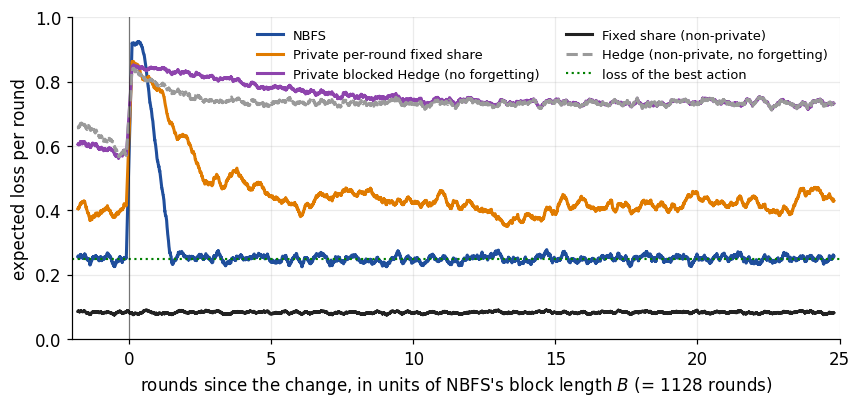

In [6]:
B = cfg["B"]; pre, post = 2 * B, 25 * B
rel = np.arange(-pre, post)
fig, ax = plt.subplots(figsize=(9, 3.8))
kern = np.ones(B // 5) / (B // 5)
for alg in ALGS:
    acc = []
    for i, e in enumerate(test_envs):
        loss = run(alg, e, cfg, etas[alg], np.random.default_rng(1000 + i))
        acc += [loss[s - pre:s + post] for s in e["switches"] if s - pre >= 0 and s + post <= len(loss)]
    m = np.convolve(np.mean(acc, 0), kern, mode="same")
    ax.plot(rel[B//5:-B//5] / B, m[B//5:-B//5], color=COLORS[alg], lw=2,
            ls="--" if "Hedge (non" in alg else "-", label=alg)
ax.axhline(1 - cfg["q"], color="green", ls=":", lw=1.4, label="loss of the best action")
ax.axvline(0, color="k", lw=0.8, alpha=0.5)
ax.set_xlabel(r"rounds since the change, in units of NBFS's block length $B$ (= %d rounds)" % B)
ax.set_ylabel("expected loss per round")
ax.set_ylim(0, 1.0); ax.set_xlim(-pre / B, post / B)
ax.legend(fontsize=8.5, ncol=2, loc="upper right")
save(fig, "fig1_recovery"); plt.show()

### Figure 2: regret on windows right after a change, against the proved bounds

The red curve is the proved floor (Corollary 1): for some loss sequence, *no* $\varepsilon$-private learner beats it. The light-blue dash-dot curve is the proved ceiling (Theorem 3): NBFS's worst-window guarantee. The empirical curves average over windows that start at a change, so they lie below the ceiling. The floor is a worst-case statement over all loss sequences, so it need not be attained in this particular environment.

The non-private learner's regret goes slightly *negative* on short windows. It beats the best fixed action by following individual clients, as explained under Figure 1.

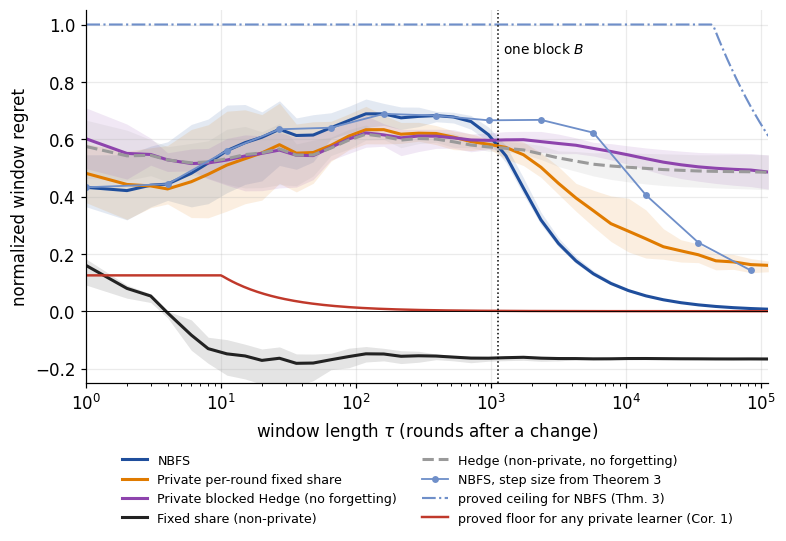

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.4))
for alg in ALGS:
    c = curves[alg]; m = c.mean(0)
    ax.plot(taus, m, color=COLORS[alg], lw=2, ls="--" if "Hedge (non" in alg else "-", label=alg)
    ax.fill_between(taus, c.min(0), c.max(0), color=COLORS[alg], alpha=0.12, lw=0)
ax.plot(th_taus, nbfs_theory.mean(0), "o-", ms=3.5, lw=1.2, color=COLORS["NBFS (theory step size)"],
        label="NBFS, step size from Theorem 3")
tt = np.logspace(0, np.log10(cfg["P"]), 300)
ax.plot(tt, upper_bound(tt, cfg["k"], cfg["K"], cfg["eps"], cfg["T"]), color="#6f8fc9", ls="-.", lw=1.4,
        label="proved ceiling for NBFS (Thm. 3)")
ax.plot(tt, lower_bound(tt, cfg["k"], cfg["K"], cfg["eps"]), color="#c0392b", lw=1.6,
        label="proved floor for any private learner (Cor. 1)")
ax.axvline(cfg["B"], color="k", ls=":", lw=1); ax.text(cfg["B"] * 1.08, 0.9, "one block $B$", fontsize=9)
ax.axhline(0, color="k", lw=0.6)
ax.set_xscale("log"); ax.set_ylim(-0.25, 1.05); ax.set_xlim(1, cfg["P"])
ax.set_xlabel(r"window length $\tau$ (rounds after a change)"); ax.set_ylabel("normalized window regret")
ax.legend(fontsize=8.3, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
save(fig, "fig2_window_regret"); plt.show()

## 5. Scaling: how the adaptation threshold depends on $k/\varepsilon$

This is the main test. We vary the tenure $k$ and the privacy level $\varepsilon$ and measure $\hat\tau_\gamma$ for three learners:

* NBFS;
* the private per-round learner (same privacy, no blocking);
* non-private fixed share.

Several $(k,\varepsilon)$ pairs share the same ratio $k/\varepsilon$, to check that the threshold depends only on that ratio. Each configuration is tuned on its own tuning seed and tested on three other seeds.

In [8]:
t0 = time.time()
CONFIGS = [(1, 2.0), (1, 1.0), (2, 1.0), (4, 1.0), (8, 1.0), (8, 0.5),     # k/eps = 0.5 ... 16
           (2, 4.0), (4, 4.0), (4, 2.0), (2, 0.5), (4, 0.5)]              # repeats of 0.5, 1, 2, 4, 8
SC_ALGS = ["NBFS", "Private per-round fixed share", "Fixed share (non-private)"]
scaling = []
for (k, eps) in CONFIGS:
    c = make_cfg(k=k, K=4, eps=eps, P_over_B=60, n_regimes=15)
    tenv = make_envs(c, [100 + k * 10 + int(eps * 10)])[0]
    envs = make_envs(c, [200 + s for s in range(3)])
    tg = np.unique(np.round(np.logspace(0, np.log10(c["P"]), 32)).astype(int))
    row = dict(k=k, eps=eps, x=k / eps, B=c["B"], P=c["P"])
    for alg in SC_ALGS:
        eta = tune(alg, tenv, c, tg, GAMMA)
        ths = [threshold(tg, cv, GAMMA) for cv in test_curves(alg, envs, c, eta, tg)]
        row[alg] = (np.mean(ths), np.std(ths))
    scaling.append(row)
    print(f"k={k} eps={eps:<4} k/eps={k/eps:<5} B={c['B']:5d}  " +
          "  ".join(f"{a.split(' (')[0][:22]}: {row[a][0]:9.0f}" for a in SC_ALGS))
print(f"time: {time.time()-t0:.0f}s")

k=1 eps=2.0  k/eps=0.5   B=   93  NBFS:       253  Private per-round fixe:       225  Fixed share:         6


k=1 eps=1.0  k/eps=1.0   B=  196  NBFS:       503  Private per-round fixe:       778  Fixed share:         5


k=2 eps=1.0  k/eps=2.0   B=  413  NBFS:      1117  Private per-round fixe:      2466  Fixed share:         3


k=4 eps=1.0  k/eps=4.0   B=  870  NBFS:      2324  Private per-round fixe:      8218  Fixed share:         1


k=8 eps=1.0  k/eps=8.0   B= 1828  NBFS:      4664  Private per-round fixe:     32208  Fixed share:         2


...

k=2 eps=4.0  k/eps=0.5   B=   93  NBFS:       256  Private per-round fixe:       221  Fixed share:         3


k=4 eps=4.0  k/eps=1.0   B=  196  NBFS:       503  Private per-round fixe:       807  Fixed share:         3


k=4 eps=2.0  k/eps=2.0   B=  413  NBFS:      1053  Private per-round fixe:      2573  Fixed share:         3


k=2 eps=0.5  k/eps=4.0   B=  870  NBFS:      2221  Private per-round fixe:      8128  Fixed share:         2


k=4 eps=0.5  k/eps=8.0   B= 1828  NBFS:      4909  Private per-round fixe:     32814  Fixed share:         3
time: 78s


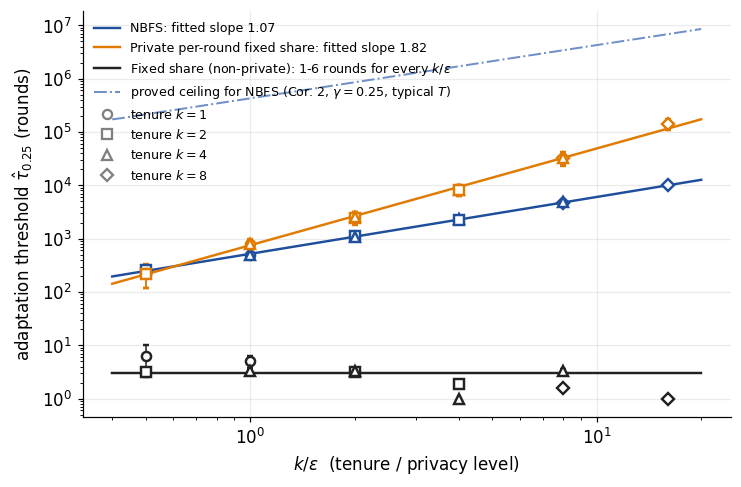

In [9]:
def fit_slope(rows, alg):
    x = np.array([r["x"] for r in rows]); y = np.array([r[alg][0] for r in rows])
    ok = np.isfinite(y)
    return np.polyfit(np.log(x[ok]), np.log(y[ok]), 1)

fig, ax = plt.subplots(figsize=(7.6, 4.8))
markers = {1: "o", 2: "s", 4: "^", 8: "D"}
for alg in SC_ALGS:
    slope, icpt = fit_slope(scaling, alg)
    for r in scaling:
        m, s = r[alg]
        ax.errorbar(r["x"], m, yerr=s, fmt=markers[r["k"]], color=COLORS[alg], ms=6, mfc="white", mew=1.6,
                    capsize=2, lw=1)
    xx = np.logspace(np.log10(0.4), np.log10(20), 50)
    if "non-private" in alg:
        lo_, hi_ = min(r[alg][0] for r in scaling), max(r[alg][0] for r in scaling)
        ax.plot(xx, np.full_like(xx, np.mean([r[alg][0] for r in scaling])), color=COLORS[alg], lw=1.6,
                label=f"{alg}: {lo_:.0f}-{hi_:.0f} rounds for every $k/\\varepsilon$")
    else:
        ax.plot(xx, np.exp(icpt) * xx ** slope, color=COLORS[alg], lw=1.6,
                label=f"{alg}: fitted slope {slope:.2f}")
xx = np.logspace(np.log10(0.4), np.log10(20), 50)
Tref = np.median([r["P"] * 15 for r in scaling])
ceil = 8 * np.ceil(4 * xx * 4 * np.log(Tref)) * (np.log(4 * Tref) + 2) / GAMMA ** 2
ax.plot(xx, ceil, color="#6f8fc9", ls="-.", lw=1.3, label=r"proved ceiling for NBFS (Cor. 2, $\gamma=0.25$, typical $T$)")
for kk, mk in markers.items():
    ax.plot([], [], mk, color="gray", mfc="white", mew=1.5, label=f"tenure $k={kk}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$k/\varepsilon$  (tenure / privacy level)")
ax.set_ylabel(r"adaptation threshold $\hat\tau_{0.25}$ (rounds)")
ax.legend(fontsize=8.3, loc="upper left", ncol=1)
save(fig, "fig3_scaling"); plt.show()

**Reading Figure 3.**

* **NBFS** has slope $\approx 1$: its adaptation window grows linearly in $k/\varepsilon$, which matches the report's floor and ceiling. Points with the same $k/\varepsilon$ but different $k$ (different marker shapes at the same $x$) land on top of each other, so tenure and privacy matter only through their ratio.
* **The private per-round learner** has slope $\approx 2$. It spends the same privacy budget, but it adds noise every round, so after $n$ rounds the noise has grown like $\sqrt n\cdot kK/\varepsilon$ while the signal has grown like $n$. It therefore needs $n\propto (k/\varepsilon)^2$ rounds. Adding up a whole block *before* adding noise is what keeps NBFS linear.
* **Non-private fixed share** is flat at a few rounds: without privacy, how long clients stay does not matter. The entire $k/\varepsilon$ dependence is the price of privacy.
* At small $k/\varepsilon$, the per-round learner is slightly *faster* than NBFS. When the noise is small, NBFS's conservative block length, which carries a $\ln T$ factor, costs more than the noise it saves. Section 6 shows that a shorter block fixes this.
* The proved floor (Corollary 1) is not drawn here because it is stated for $\gamma<1/8$. For $\varepsilon=1$, $k=5$, $K=4$ it equals $10$ rounds, far below every private point.

## 6. Is the block length in the report a good choice?

We fix $\varepsilon=1$, $k=5$ and vary NBFS's block length $B$ from a single round up to $4\times$ the value used in the report, $B^\star=\lceil 4kK\ln T/\varepsilon\rceil$. The step size is tuned for each $B$. Very small blocks behave like the per-round learner, because noise piles up. Very large blocks waste time, because the learner is frozen. The optimum lies in between.

time: 19s


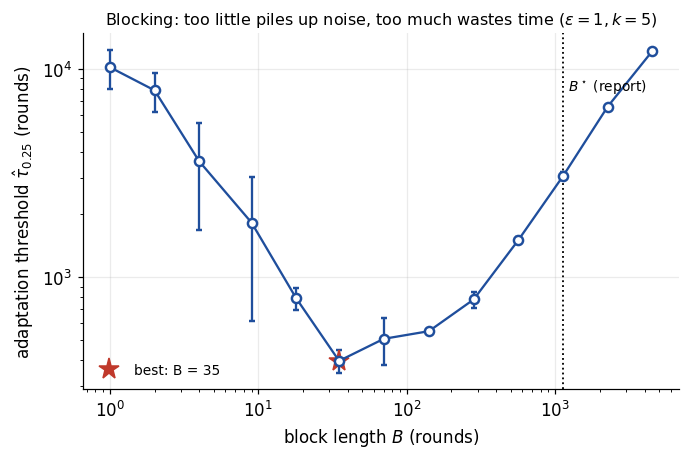

In [10]:
t0 = time.time()
mults = 2.0 ** np.arange(-10, 3)
Bs = np.unique(np.maximum(1, np.round(cfg["B"] * mults)).astype(int))
res_B = []
for B in Bs:
    eta = tune("NBFS", tune_env, cfg, taus, GAMMA, B=B)
    ths = [threshold(taus, cv, GAMMA) for cv in test_curves("NBFS", test_envs[:3], cfg, eta, taus, B=B)]
    res_B.append((B, np.mean(ths), np.std(ths)))
res_B = np.array(res_B)
print(f"time: {time.time()-t0:.0f}s")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.errorbar(res_B[:, 0], res_B[:, 1], yerr=res_B[:, 2], fmt="o-", color=COLORS["NBFS"], mfc="white", mew=1.6, capsize=2)
ax.axvline(cfg["B"], color="k", ls=":", lw=1.2); ax.text(cfg["B"] * 1.08, ax.get_ylim()[1] * 0.6, r"$B^\star$ (report)", fontsize=9)
ibest = np.nanargmin(res_B[:, 1])
ax.plot(res_B[ibest, 0], res_B[ibest, 1], "*", ms=14, color="#c0392b", label=f"best: B = {int(res_B[ibest,0])}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("block length $B$ (rounds)"); ax.set_ylabel(r"adaptation threshold $\hat\tau_{0.25}$ (rounds)")
ax.set_title(r"Blocking: too little piles up noise, too much wastes time ($\varepsilon=1,k=5$)", fontsize=10.5)
ax.legend(fontsize=9)
save(fig, "fig4_block_size"); plt.show()

## 7. Numbers for the report

**Reading Figure 4.** The threshold is U-shaped in $B$. With $B=1$ (the per-round learner) noise piles up; with very large $B$ the learner is frozen for too long. To the right of the optimum the threshold grows roughly in proportion to $B$, as the "freezing is forced" argument predicts. The optimum is broad, from a few dozen to about a hundred and fifty rounds, roughly an order of magnitude shorter than the $B^\star$ used in the proof. Most of the gap is the $\ln T$ factor and the constant $4$ in $B^\star$, both of which come from how the proof controls the clipping error. This suggests the $\ln T$ factor in the upper bound may be an artifact of the analysis.

In [11]:
print("Main configuration (eps=1, k=5, K=4): B* =", cfg["B"], " regime length P =", cfg["P"])
for alg in ALGS:
    th = [threshold(taus, c, GAMMA) for c in curves[alg]]
    s = "never adapts" if not np.all(np.isfinite(th)) else f"{np.mean(th):8.0f} rounds  (= {np.mean(th)/cfg['B']:.2f} B*)"
    print(f"  {alg:40s} {s}")
print(f"  {'NBFS, theory step size':40s} {threshold(th_taus, nbfs_theory.mean(0), GAMMA):8.0f} rounds")
print("\nScaling with k/eps (fitted log-log slopes):")
for alg in SC_ALGS[:2]:
    print(f"  {alg:40s} slope = {fit_slope(scaling, alg)[0]:.2f}")
v = [r["Fixed share (non-private)"][0] for r in scaling]
print(f"  {'Fixed share (non-private)':40s} thresholds between {min(v):.0f} and {max(v):.0f} rounds (no trend)")
print(f"\nBlock size: best B = {int(res_B[ibest,0])} vs report's B* = {cfg['B']} "
      f"(threshold {res_B[ibest,1]:.0f} vs {res_B[np.argmin(np.abs(res_B[:,0]-cfg['B'])),1]:.0f} rounds)")

Main configuration (eps=1, k=5, K=4): B* = 1128  regime length P = 113217
  NBFS                                         3004 rounds  (= 2.66 B*)
  Private per-round fixed share               13965 rounds  (= 12.38 B*)
  Private blocked Hedge (no forgetting)    never adapts
  Fixed share (non-private)                       1 rounds  (= 0.00 B*)
  Hedge (non-private, no forgetting)       never adapts
  NBFS, theory step size                      32416 rounds

Scaling with k/eps (fitted log-log slopes):
  NBFS                                     slope = 1.07
  Private per-round fixed share            slope = 1.82
  Fixed share (non-private)                thresholds between 1 and 6 rounds (no trend)

Block size: best B = 35 vs report's B* = 1128 (threshold 396 vs 3052 rounds)


## 8. Caveats

* **Metric.** We measure windows that start at a change, averaged over changes. The theory bounds the *worst* window, so the empirical curves sit below the proved ceiling, as they should.
* **Tuned step sizes.** All learners except non-private Hedge use a step size picked on a separate tuning seed. With the exact step size from Theorem 3, NBFS adapts more slowly (light-blue dots in Figure 2), which shows how conservative that constant is.
* **Accuracy level.** We use $\gamma=0.25$ for the threshold, while the definition in the report uses $\gamma<1/8$. Smaller $\gamma$ moves every threshold up, but it should not change the slopes.
* **One environment.** The floor of Theorem 1 is a worst case over all loss sequences. This simulation uses one natural churning population, so it illustrates the scaling rather than proving it.